# Data Info

## Key Attributes

### Customer Demographics
* **Geographic data:** Gender, city, state, zip code, and geographic coordinates (latitude and longitude).

### Subscription Information
* **Contract terms:** Details about the contract type (month-to-month, one-year, two-year).
* **Billing details:** Payment method (electronic check, mailed check, credit card, etc.) and monthly charges.

### Churn Data
* **Status indicators:** Indicates whether the customer has churned (Yes/No).
* **Predictive metrics:** A score predicting their likelihood to churn, reasons for leaving, and the Customer Lifetime Value (CLTV).

### Churn Reasons
* **Exit factors:** Specific reasons for churn, such as competitors offering better deals, service dissatisfaction, or moving to a new location.

---

## Key Columns

* **CustomerID:** Unique identifier for each customer.
* **Gender:** Gender of the customer.
* **Contract:** The contract type (Month-to-month, One year, etc.).
* **Payment Method:** How the customer makes payments (e.g., Bank transfer, Credit card).
* **Monthly Charges:** The amount the customer is billed monthly.
* **Total Charges:** Cumulative amount billed to the customer.
* **Churn Label:** Indicates whether the customer has churned (Yes/No).
* **Churn Reason:** Reason why the customer churned.

---

## Dataset link
* https://www.kaggle.com/datasets/abdallahwagih/telco-customer-churn


# Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset

In [2]:
%pip install openpyxl


Note: you may need to restart the kernel to use updated packages.


In [3]:
data = pd.read_excel('Telco_customer_churn.xlsx')

In [4]:
data.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


# Data Preprocessing & EDA

In [5]:
data.shape

(7043, 33)

In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

In [7]:
data['Total Charges'] = data['Total Charges'].apply(pd.to_numeric, errors='coerce')

In [8]:
data['Churn Label'].head()

0    Yes
1    Yes
2    Yes
3    Yes
4    Yes
Name: Churn Label, dtype: str

In [9]:
data['Churn Label'] = data['Churn Label'].map({
    'No': 0,
    'Yes': 1
})

In [10]:
data['Churn Label'].head()

0    1
1    1
2    1
3    1
4    1
Name: Churn Label, dtype: int64

In [11]:
data.columns.tolist()

['CustomerID',
 'Count',
 'Country',
 'State',
 'City',
 'Zip Code',
 'Lat Long',
 'Latitude',
 'Longitude',
 'Gender',
 'Senior Citizen',
 'Partner',
 'Dependents',
 'Tenure Months',
 'Phone Service',
 'Multiple Lines',
 'Internet Service',
 'Online Security',
 'Online Backup',
 'Device Protection',
 'Tech Support',
 'Streaming TV',
 'Streaming Movies',
 'Contract',
 'Paperless Billing',
 'Payment Method',
 'Monthly Charges',
 'Total Charges',
 'Churn Label',
 'Churn Value',
 'Churn Score',
 'CLTV',
 'Churn Reason']

In [12]:
data.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7032.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,2283.300441,0.265370,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,2266.771362,0.441561,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,18.800000,0.000000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,401.450000,0.000000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,1397.475000,0.000000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,3794.737500,1.000000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,8684.800000,1.000000,1.000000,100.000000,6500.000000


In [13]:
data.isnull().sum()

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges          11
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64

In [14]:
data.duplicated().sum()

np.int64(0)

In [15]:
# Check whether CustomerID is unique
data["CustomerID"].is_unique

True

In [16]:
data["Churn Label"].value_counts()

Churn Label
0    5174
1    1869
Name: count, dtype: int64

*Our data is slighly imbalanced, we will figuref it out later in the process to handle it*

# Visualization

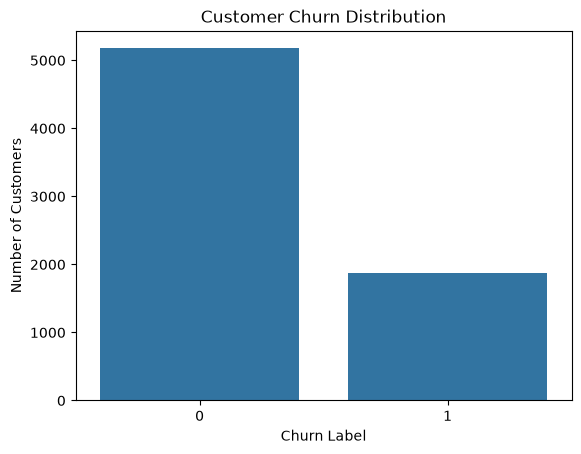

In [17]:
sns.countplot(data=data, x="Churn Label")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Label")
plt.ylabel("Number of Customers")
plt.show()

In [18]:
churn_rate = (
    data["Churn Label"].eq("Yes").mean() * 100
)

print(f"Churn rate: {churn_rate:.2f}%")

Churn rate: 0.00%


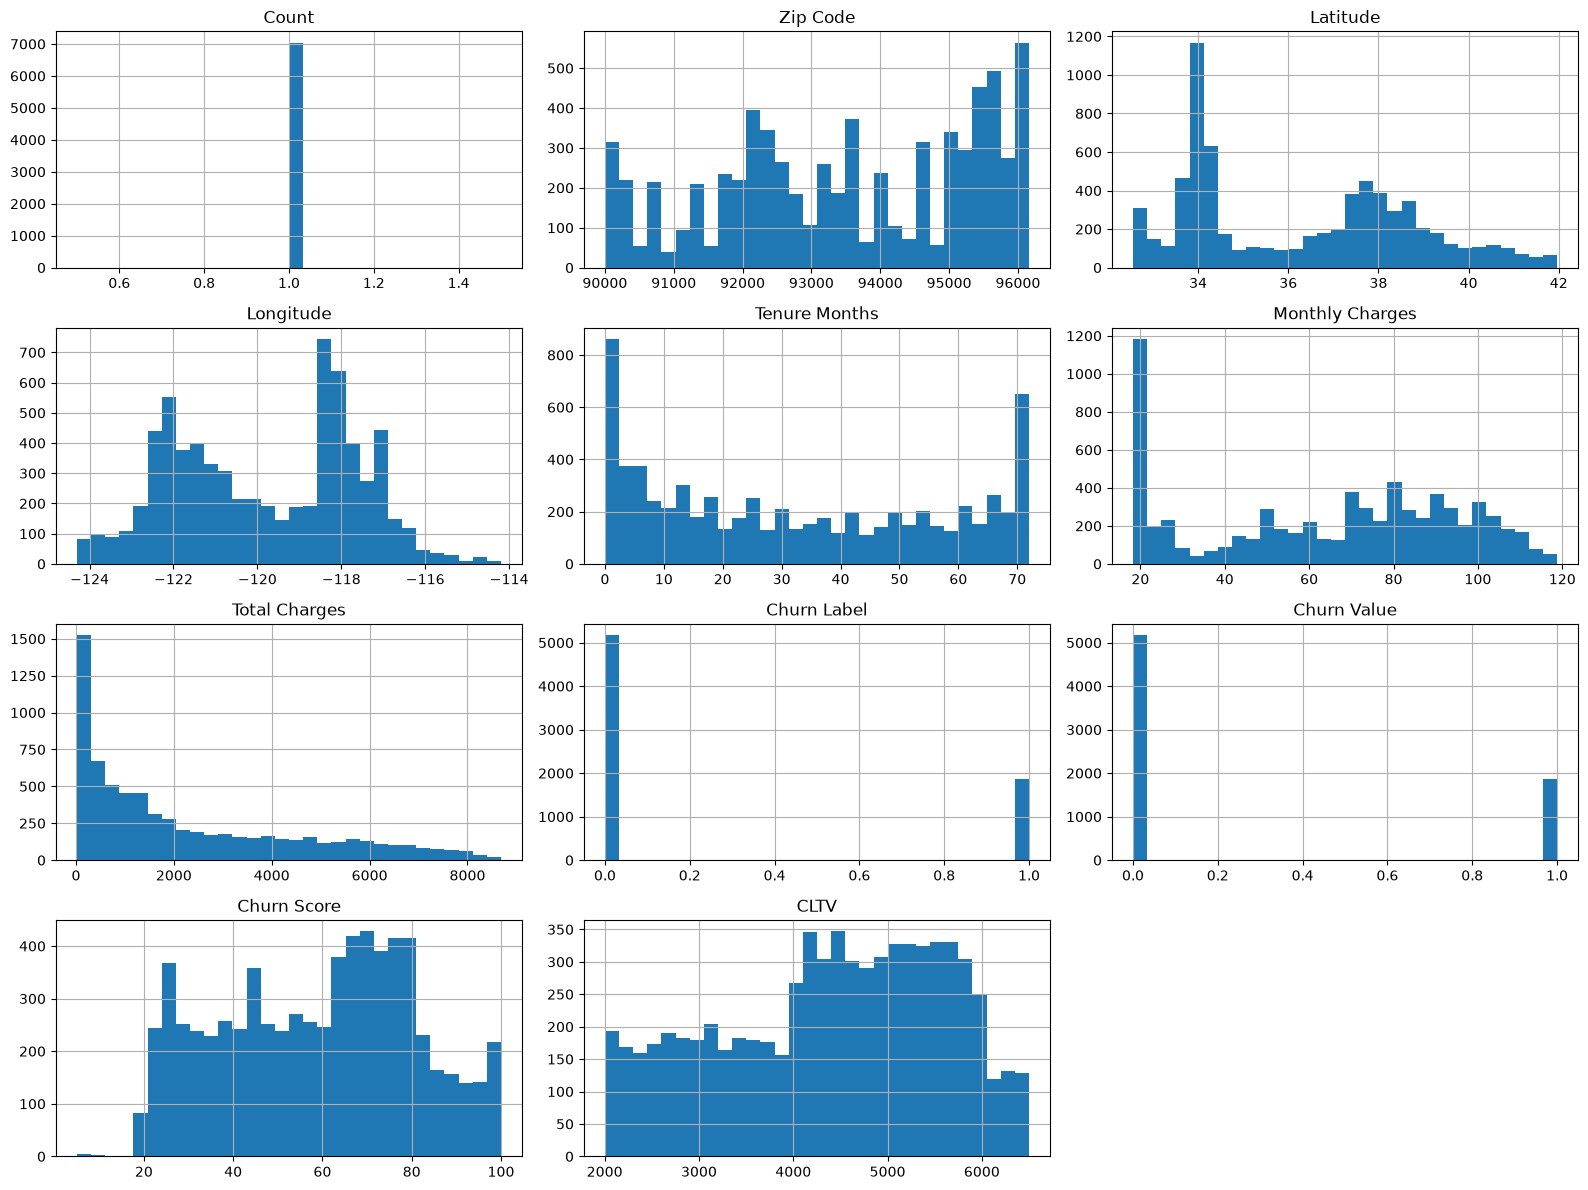

In [19]:
numerical_cols = data.select_dtypes(
    include="number"
).columns

data[numerical_cols].hist(
    figsize=(16, 12),
    bins=30
)

plt.tight_layout()
plt.savefig("my_plot.png", dpi=300, bbox_inches="tight")
plt.show()



*Since we also are going to use Logistic Regg to train our model, we will do distribution transformation to make like bell-shaped*

In [20]:
print(data['Total Charges'])

0        108.15
1        151.65
2        820.50
3       3046.05
4       5036.30
         ...   
7038    1419.40
7039    1990.50
7040    7362.90
7041     346.45
7042    6844.50
Name: Total Charges, Length: 7043, dtype: float64


In [21]:
data['Tenure Months'] = np.log(data['Tenure Months']+1)
data['Monthly Charges'] = np.log(data['Monthly Charges']+1)
data['Total Charges'] = np.log(data['Total Charges']+1)

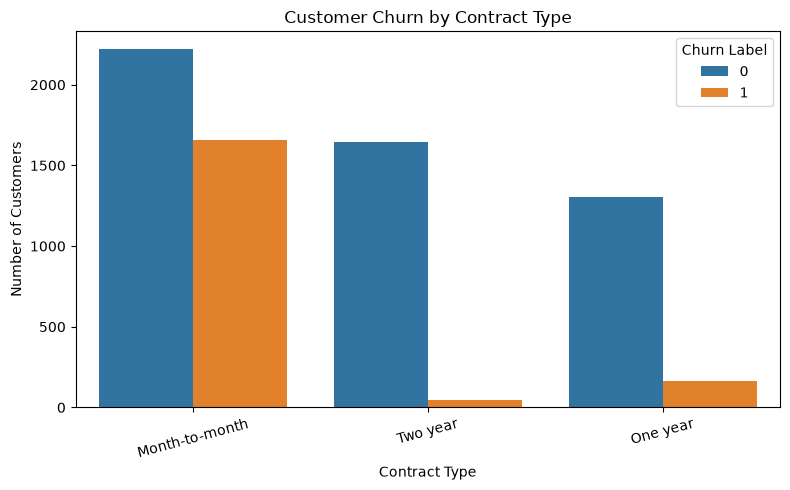

In [22]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=data,
    x="Contract",
    hue="Churn Label"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# Correlation

In [23]:
data.corr(numeric_only=True)

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV
Count,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zip Code,NaN,1.000000,0.895743,-0.784271,0.005698,-0.008049,0.001108,0.003346,0.003346,-0.002769,-0.003562
Latitude,NaN,0.895743,1.000000,-0.876779,0.002772,-0.023160,-0.006305,-0.003384,-0.003384,-0.007684,0.000886
Longitude,NaN,-0.784271,-0.876779,1.000000,-0.003265,0.029412,0.008015,0.004594,0.004594,0.004260,0.000485
Tenure Months,NaN,0.005698,0.002772,-0.003265,1.000000,0.194668,0.924617,-0.373324,-0.373324,-0.231731,0.303181
Monthly Charges,NaN,-0.008049,-0.023160,0.029412,0.194668,1.000000,0.546079,0.210109,0.210109,0.142195,0.076281
Total Charges,NaN,0.001108,-0.006305,0.008015,0.924617,0.546079,1.000000,-0.241908,-0.241908,-0.145740,0.275471
Churn Label,NaN,0.003346,-0.003384,0.004594,-0.373324,0.210109,-0.241908,1.000000,1.000000,0.664897,-0.127463
Churn Value,NaN,0.003346,-0.003384,0.004594,-0.373324,0.210109,-0.241908,1.000000,1.000000,0.664897,-0.127463
Churn Score,NaN,-0.002769,-0.007684,0.004260,-0.231731,0.142195,-0.145740,0.664897,0.664897,1.000000,-0.079782


# Train Split

In [24]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate

In [25]:
# Define X and y
X = data.drop(columns=[
    'CustomerID',
    'Churn Label',
    'Churn Value',
    'Churn Score',
    'Churn Reason',
    'Zip Code',
    'Latitude',
    'Longitude',
    'Gender',
    'City'
    
    
])

y = data['Churn Label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Custom Transformer (Pipeline) & Model Train

In [26]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

In [27]:
# Combine X and y

numer_cols = X.select_dtypes(include='number').columns

cater_cols = X.select_dtypes(
    include=['object', 'category', 'bool']
).columns



C:\Users\User\AppData\Local\Temp\ipykernel_5784\3281930701.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cater_cols = X.select_dtypes(


In [28]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

numer_pipeline = Pipeline(steps =[
    ('impute', SimpleImputer(strategy='mean')),
    ('scale',StandardScaler())
])

cater_pipeline = Pipeline(steps =[
    ('impute', SimpleImputer(strategy='most_frequent')),
    ('one-hot-encoder',OneHotEncoder(handle_unknown='ignore',sparse_output=False))
])

In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

In [30]:
cols_transformer = ColumnTransformer(transformers=[
     ('num_pipeline' , numer_pipeline, numer_cols),
    ('cater_pipeline',cater_pipeline, cater_cols),
],
                                     remainder = 'drop',
                                     n_jobs= -1 
                                    )

# Logistic Regression

In [31]:
from sklearn.linear_model import LogisticRegression

In [32]:
model = LogisticRegression(class_weight="balanced", max_iter=1000)

pipe_1 = make_pipeline(cols_transformer, model)

In [33]:
#Train using LogisticRegg with train data
pipe_1.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['Count','Country','State',...,'Monthly Charges','Total Charges','CLTV']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_pipeline', ...), ('cater_pipeline', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",-1
,"remainder remainder: {'dr

In [34]:
#Train data score
X_train_prediction = pipe_1.predict(X_train)
training_data_accuracy= accuracy_score(X_train_prediction, y_train)

In [35]:
print(training_data_accuracy)

0.8244586439474618


In [36]:
# Accuracy on the test data
X_test_prediction = pipe_1.predict(X_test)
test_data_accuracy = accuracy_score(X_test_prediction, y_test)

In [37]:
print('Accuracy on test data : ',test_data_accuracy)

Accuracy on test data :  0.7544357700496807


In [38]:
from sklearn.metrics import classification_report

X_train_prediction = pipe_1.predict(X_train)
X_test_prediction = pipe_1.predict(X_test)

print("Training Performance:")
print(classification_report(y_train, X_train_prediction))

print("Testing Performance:")
print(classification_report(y_test, X_test_prediction))

Training Performance:
              precision    recall  f1-score   support

           0       0.95      0.80      0.87      4139
           1       0.62      0.88      0.73      1495

    accuracy                           0.82      5634
   macro avg       0.78      0.84      0.80      5634
weighted avg       0.86      0.82      0.83      5634

Testing Performance:
              precision    recall  f1-score   support

           0       0.90      0.75      0.82      1035
           1       0.53      0.76      0.62       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.77      1409



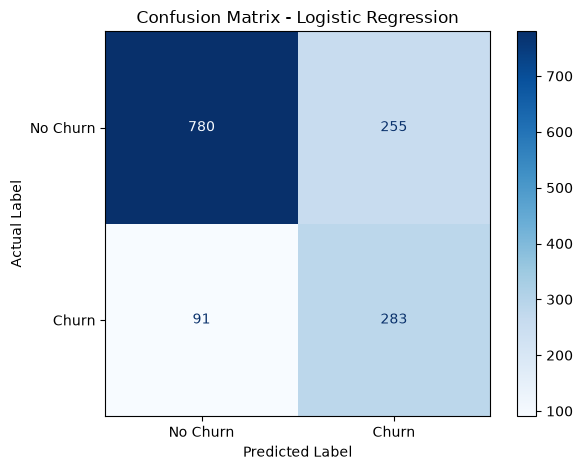

In [39]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Create confusion matrix
cm = confusion_matrix(y_test, X_test_prediction)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Churn', 'Churn']
)

disp.plot(cmap='Blues', values_format='d')

plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()

The model made 1,409 predictions in total:
- 1,063 correct predictions: 780 non-churners and 283 churners.
- 346 incorrect predictions: 91 false positives and 255 false negatives.

We will explore other model.

# Balanced Random Forest (BRF)

In [40]:
from imblearn.ensemble import BalancedRandomForestClassifier

In [41]:
model2 = BalancedRandomForestClassifier(random_state=42)

pipe_2 = make_pipeline(cols_transformer, model2)

In [42]:
#Train using 2nd Model with train data
pipe_2.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('balancedrandomforestclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['Count','Country','State',...,'Monthly Charges','Total Charges','CLTV']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_pipeline', ...), ('cater_pipeline', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",-1
,"remainder rem

In [43]:
#Train data score
X_train_prediction = pipe_2.predict(X_train)
training_data_accuracy= accuracy_score(X_train_prediction, y_train)

In [44]:
print(training_data_accuracy)

0.9407170749023784


In [45]:
# Accuracy on the test data
X_test_prediction = pipe_2.predict(X_test)
test_data_accuracy = accuracy_score(X_test_prediction, y_test)

In [46]:
print('Accuracy on test data : ',test_data_accuracy)

Accuracy on test data :  0.7693399574166075


In [47]:
X_train_prediction = pipe_2.predict(X_train)
X_test_prediction = pipe_2.predict(X_test)

print("Training Performance:")
print(classification_report(y_train, X_train_prediction))

print("Testing Performance:")
print(classification_report(y_test, X_test_prediction))

Training Performance:
              precision    recall  f1-score   support

           0       1.00      0.92      0.96      4139
           1       0.82      1.00      0.90      1495

    accuracy                           0.94      5634
   macro avg       0.91      0.96      0.93      5634
weighted avg       0.95      0.94      0.94      5634

Testing Performance:
              precision    recall  f1-score   support

           0       0.89      0.79      0.83      1035
           1       0.55      0.72      0.62       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.80      0.77      0.78      1409



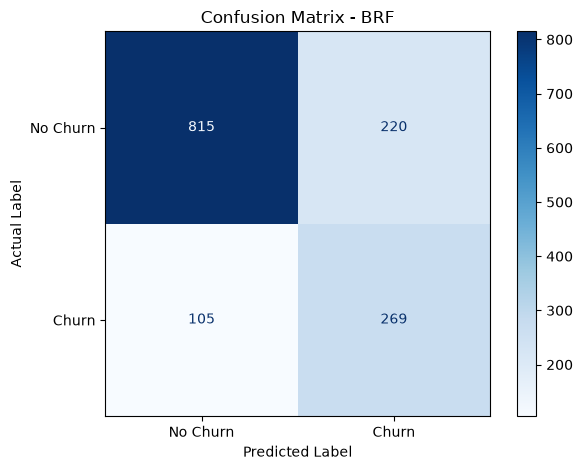

In [48]:
# Create confusion matrix
cm = confusion_matrix(y_test, X_test_prediction)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Churn', 'Churn']
)

disp.plot(cmap='Blues', values_format='d')

plt.title('Confusion Matrix - BRF')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()

The second model made 1,409 predictions in total:
- 1,084 correct predictions: 815 non-churners and 269 churners.
- 325 incorrect predictions: 105 false positives and 220 false negatives.

**The second model performs better overall in accuracy and makes fewer incorrect predictions**



# XGBoost

In [49]:
from xgboost import XGBClassifier

In [50]:
model3 = XGBClassifier(random_state=42)

pipe_3 = make_pipeline(cols_transformer, model3)

In [51]:
#Train using 2nd Model with train data
pipe_3.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('xgbclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['Count','Country','State',...,'Monthly Charges','Total Charges','CLTV']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num_pipeline', ...), ('cater_pipeline', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",-1
,"remainder remainder: {'drop', 

In [52]:
#Train data score
X_train_prediction = pipe_3.predict(X_train)
training_data_accuracy= accuracy_score(X_train_prediction, y_train)

In [53]:
print(training_data_accuracy)

0.9678736244231452


In [54]:
# Accuracy on the test data
X_test_prediction = pipe_3.predict(X_test)
test_data_accuracy = accuracy_score(X_test_prediction, y_test)

In [55]:
print('Accuracy on test data : ',test_data_accuracy)

Accuracy on test data :  0.7863733144073811


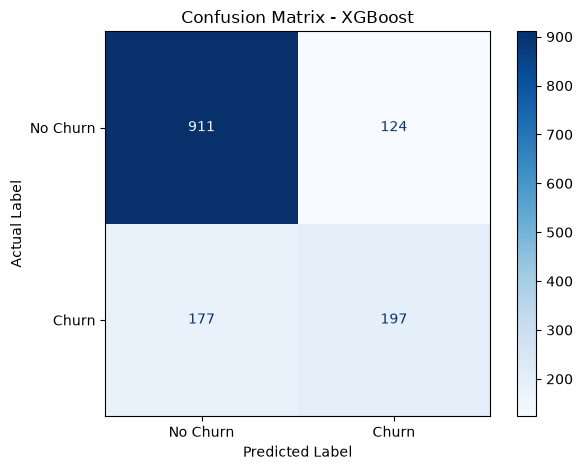

In [56]:
# Create confusion matrix
cm = confusion_matrix(y_test, X_test_prediction)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Churn', 'Churn']
)

disp.plot(cmap='Blues', values_format='d')

plt.title('Confusion Matrix - XGBoost')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()

* XGBoost: Achieves the highest accuracy and precision. It makes fewer false-positive predictions, but misses more actual churners.



* Model 2: Has the highest F1-score, providing the best balance between precision and recall among the three models.



* Model 1: Has the highest recall, meaning it identifies the greatest proportion of actual churners.


## Which Model Is the Best?

The three classification models were evaluated using confusion matrices to compare their performance in predicting customer churn.

### 1. Best Overall Balance: Logistic Regression

Logistic Regression achieved the highest recall of **75.7%** and the highest F1-score of approximately **62.1%** among the three models. It correctly identified 283 out of 374 actual churners, making it the strongest option when identifying customers who may leave is important.

### 2. Best for Identifying Non-Churners: XGBoost

XGBoost correctly classified 911 non-churners and achieved the highest accuracy of approximately **78.7%**. It also had the fewest false positives, with 124 non-churners incorrectly predicted as churners. However, its recall for churners was lower at **52.7%**, meaning it missed more actual churners.

### 3. Best Balance Between Precision and Recall: BRF

BRF achieved a churn precision of approximately **55.0%** and an F1-score of approximately **62.8%**. It provides a more balanced performance than XGBoost for identifying churners, although its recall of **71.9%** is lower than Logistic Regression.

### Overall Conclusion

- **Logistic Regression:** Best for identifying actual churners, with the highest recall of 75.7%.
- **BRF:** Best overall balance based on the highest F1-score of approximately 62.8%.
- **XGBoost:** Best accuracy at approximately 78.7%, with the fewest false positives, but lower churn recall.

Overall, **BRF is the preferred model based on the F1-score**, while Logistic Regression may be more suitable if the main objective is to identify as many potential churners as possible. The final choice depends on the business objective and the relative cost of missed churners versus false alarms.
